In [ ]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

In [ ]:
def DIV(arr, spreading_percentage, tpm_or_count, ceil=False, min_eve=0):
    """
    Adaptation of Shannon's eveness index.
    Computes array's isoform diversity.
    
    Args:
        arr: An array of isoform expression.
        spreading_percentage: An int which decides the spreading percentage we want to spread.
        tpm_or_count: A string which decides whether to read TPM files or Transcript Read Counts file.
        ceil: A boolean which decides whether to use ceiling.
        min_eve: A boolean which decides whether to calculate the minimum diversity.
    
    Returns:
        An number which represent the diversity of isoforms in a selected gene.
    """
    
    # Calculating how many actual splice sites in total, meaning sites with readings > 0. We want that len will be > 1
    # We don't want to use spreading on genes with 1 isoforms, this will return a value with maximum diversity - we return 0 diversity instead.
    if len(np.array(arr)[np.array(arr)>0]) <= 1:
        return 0   
    
    # Calculating the percentage of read counts we want to spread 
    p = ((sum(arr)*(spreading_percentage/100)) / len(arr))
    
    # Decides whether to use ceiling or not.
    # If we:
    #   use count data, 
    #   define ceil==true 
    #   and 0<p<1 (greater than 0 in case we want no spreading), 
    # then:
    #   ceiling is applied
    if tpm_or_count == 'count' and ceil and (0<p<1):
        p = 1
    

    if min_eve: # If true, then we calcualte the minimum diversity
        ''' minimum diversity: one isoform that contains all the reads in it. 
        for example: [1000, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
        we take the minimum diversity of an arary. 
        for example: [250, 250, 250, 250, 0, 0, 0, 0, 0, 0, 0, 0, 0]
        and we measure the minimum diversity as it it has one isoform that contains all the reads in the array
        like in the first example. The first eleemnt will have the sum of reads.
        we add the p (spreading percentage) let's say that p=1%
        for example: [1000+10, 0+10, 0+10, 0+10, 0+10, 0+10, 0+10, 0+10, 0+10, 0+10, 0+10, 0+10, 0+10]
        '''
        arr_new = np.array([sum(arr)+p] + [p for _ in range(1,len(arr))] )
    else:
        arr_new = np.array(arr) + p # spreading
    
    
    possible_ss = len(arr_new) #computing how many POSSIBLE splice sites (including sites with 0 readings)
    total_reads = sum(arr_new) #computing how many readings in TOTAL.

    
    #computing shannon's eveness index
    index_value = 0
    for splice_site in arr_new:
        x = splice_site/(total_reads)
        if x!=0:
            index_value += (x)*(math.log(x)) # default base is e
   
    return (round(-1*index_value, 3) / math.log(possible_ss)) # default base is e

# simulated data

In [24]:
indices_names = ['i' + str(x) for x in range(10)]
sim_df = pd.DataFrame(columns=indices_names) 
highest_val = 10
for nrow in range(50):
    highest_val *= 1.1 # geometric slope
    a = np.array([int(highest_val/(2**p)) for p in range(10)]) # exponential slope slope
    a[a==0] = 1
    sim_df.loc[nrow] = a     # switch 0s by 1s
sim_df

,i0,i1,i2,i3,i4,i5,i6,i7,i8,i9
0,11,5,2,1,1,1,1,1,1,1
1,12,6,3,1,1,1,1,1,1,1
2,13,6,3,1,1,1,1,1,1,1
3,14,7,3,1,1,1,1,1,1,1
4,16,8,4,2,1,1,1,1,1,1
5,17,8,4,2,1,1,1,1,1,1
6,19,9,4,2,1,1,1,1,1,1
7,21,10,5,2,1,1,1,1,1,1
8,23,11,5,2,1,1,1,1,1,1
9,25,12,6,3,1,1,1,1,1,1


In [30]:
sim_df['DIV_1'] = sim_df[indices_names].apply(lambda row: DIV(arr=row, spreading_percentage=1, tpm_or_count='count'), axis='columns')
sim_df

,i0,i1,i2,i3,i4,i5,i6,i7,i8,i9,DIV_1
0,11,5,2,1,1,1,1,1,1,1,0.779993
1,12,6,3,1,1,1,1,1,1,1,0.771307
2,13,6,3,1,1,1,1,1,1,1,0.757410
3,14,7,3,1,1,1,1,1,1,1,0.741775
4,16,8,4,2,1,1,1,1,1,1,0.741775
5,17,8,4,2,1,1,1,1,1,1,0.731352
6,19,9,4,2,1,1,1,1,1,1,0.710506
7,21,10,5,2,1,1,1,1,1,1,0.697911
8,23,11,5,2,1,1,1,1,1,1,0.681408
9,25,12,6,3,1,1,1,1,1,1,0.684014


[Text(0.5, 0, 'array #'), Text(0, 0.5, 'Diversity index')]

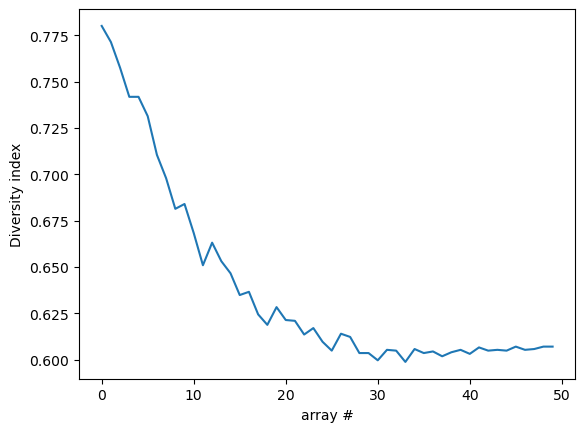

In [34]:
fig, ax = plt.subplots()
sns.lineplot(data=sim_df, x=sim_df.index, y='DIV_1')
ax.set(xlabel = 'array #', ylabel = 'Diversity index')

In [20]:
sim_df.reset_index()

,index,i0,i1,i2,i3,i4,i5,i6,i7,i8,i9,DIV_1
0,0,11,5,2,1,1,1,1,1,1,1,0.779993
1,1,12,6,3,1,1,1,1,1,1,1,0.771307
2,2,13,6,3,1,1,1,1,1,1,1,0.757410
3,3,14,7,3,1,1,1,1,1,1,1,0.741775
4,4,16,8,4,2,1,1,1,1,1,1,0.741775
5,5,17,8,4,2,1,1,1,1,1,1,0.731352
6,6,19,9,4,2,1,1,1,1,1,1,0.710506
7,7,21,10,5,2,1,1,1,1,1,1,0.697911
8,8,23,11,5,2,1,1,1,1,1,1,0.681408
9,9,25,12,6,3,1,1,1,1,1,1,0.684014


# biological data

How I made the demo data:   
```
zcat /lustre1/home/martinmikl/sshanas/outsourcedata/pipeline_2025/outputdir.1/readtpm_t.csv.gz | cut -d ',' -f 1-10 > /lustre1/home/martinmikl/sshanas/outsourcedata/demo/input_for_isoform_div.csv
zcat /lustre1/home/martinmikl/sshanas/outsourcedata/pipeline_2025/outputdir.5/other_and_HK-RP/tpm.csv.gz | cut -d ',' -f 1-10 > /lustre1/home/martinmikl/sshanas/outsourcedata/demo/input_for_transcriptome_div.csv
```

In [72]:
from sklearn.preprocessing import MinMaxScaler
def scale_with_MinMax(smpl,isoforms_df,minval = 10**-2):
    scaler = MinMaxScaler(feature_range=(minval, 1))
    plot_data = isoforms_df[[smpl]]
    plot_data = plot_data[plot_data > 0].dropna().sort_values(plot_data.columns[0], ascending=False)

    plot_data = plot_data.assign(minmax = scaler.fit_transform(plot_data[[smpl]]))
    plot_data = plot_data.assign(percentiles = plot_data['minmax'].rank(pct=True, method='first') * 100).sort_values('minmax', ascending=True)
    return plot_data

def DIV_description(smpl:str, isoforms_df):
    plot_data = isoforms_df[[smpl]]
    plot_data = plot_data[plot_data > 0].dropna().sort_values(plot_data.columns[0], ascending=False)
    plot_data = plot_data.assign(isof_idx = range(len(plot_data)), 
                                log2 = plot_data[plot_data.columns[0]].apply(lambda x: math.log2(x+1)))
    color_palette = {t:sns.color_palette('plasma_r', len(plot_data)).as_hex()[i] for i,t in enumerate(plot_data.isof_idx) }
    
    fig, ax = plt.subplots(figsize=(1.5, 1.5))
    plot_data.plot.bar(x="isof_idx", y="log2", rot=0, ax = ax, color = plot_data.reset_index().index.map(color_palette), legend=False, width=0.9)
    ax.set_xticks([])

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)     
    ax.patch.set_facecolor('None')
    ax.set(ylabel='log2(I-TPM+1)', xlabel='isoform #')

    fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
    plot_data[[plot_data.columns[0], 'isof_idx']].set_index('isof_idx').T.plot(kind='barh', stacked=True, legend=False, color=color_palette, width=0.1, ax=ax) # , edgecolor='whitesmoke'
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)     
    ax.patch.set_facecolor('None')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(x=0.45, y=0.05, s='I-TPM RA', transform=ax.transAxes, ha = 'center')

    plot_data = scale_with_MinMax(smpl, isoforms_df=isoforms_df)

    fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
    sns.lineplot(data=plot_data, x='percentiles', y='minmax', color='#392A48', marker='h', markersize=3, linewidth = 0.5, alpha = 1, markeredgewidth=0,
                ax =ax)
    ax.set_yscale('log')
    ax.set(ylabel='I-TPM norm.', xlabel='I-TPM pct.')
    sns.despine()



In [ ]:
# load the input files
input_for_isoform_div = pd.read_csv('input_for_isoform_div.csv')
input_for_transcriptome_div = pd.read_csv('input_for_transcriptome_div.csv', index_col=0)

## isoform diversity calculation  
with visual discription of isoform diversity - the isoform expression and thier relative aboundances

In [ ]:
I_DIV = input_for_isoform_div.groupby('accession_number').agg(lambda x: DIV(arr=x, spreading_percentage=1, tpm_or_count='TPM'))

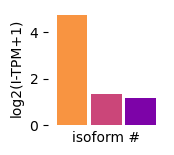

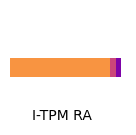

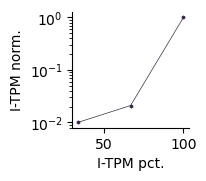

In [ ]:
DIV_description(smpl='GTEX-111FC-0126-SM-5N9DL', isoforms_df=input_for_isoform_div.loc[input_for_isoform_div['accession_number']=='ENSG00000000419']) # gene of example with 3 expressed isoforms

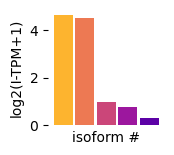

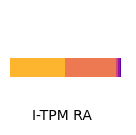

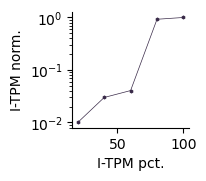

In [75]:
DIV_description(smpl='GTEX-111FC-0126-SM-5N9DL', isoforms_df=input_for_isoform_div.loc[input_for_isoform_div['accession_number']=='ENSG00000148290']) # gene of example with 5 expressed isoforms

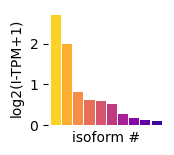

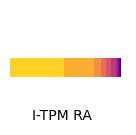

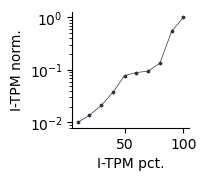

In [89]:
DIV_description(smpl='GTEX-111FC-0126-SM-5N9DL', isoforms_df=input_for_isoform_div.loc[input_for_isoform_div['accession_number']=='ENSG00000138399']) # gene of example with 10 expressed isoforms

,GTEX-111FC-0126-SM-5N9DL,GTEX-111FC-0226-SM-5N9B8,GTEX-111FC-0326-SM-5GZZ1,GTEX-111FC-0426-SM-5N9CV,GTEX-111FC-0526-SM-5GZZ8,GTEX-111FC-0626-SM-5N9CU,GTEX-111FC-0826-SM-5GZWO,GTEX-111FC-1126-SM-5GZWU,GTEX-111FC-2526-SM-5GZXU
accession_number,,,,,,,,,
ENSG00000000419,0.243336,0.271800,0.353842,0.336541,0.435884,0.287985,0.313658,0.444814,0.412444
ENSG00000000457,0.887266,0.777290,0.643703,0.865520,0.728205,0.824511,0.589026,0.902800,0.681604
ENSG00000000460,0.586649,0.728647,0.613501,0.639898,0.649001,0.477876,0.497446,0.581188,0.574816
ENSG00000000938,0.506704,0.633637,0.549871,0.355104,0.565802,0.605372,0.426022,0.697360,0.579677
ENSG00000000971,0.612805,0.581551,0.505090,0.500625,0.604992,0.510113,0.592713,0.560343,0.682011
...,...,...,...,...,...,...,...,...,...
ENSG00000284465,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000284484,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000284526,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


## transcriptome diversity calculation
with visual discription of transcriptome diversity - the gene expression and thier relative aboundances per sample (per transcriptome)

In [ ]:
T_DIV = input_for_transcriptome_div.apply(lambda x: DIV(arr=x, spreading_percentage=1, tpm_or_count='TPM'), axis='rows')
T_DIV

GTEX-111FC-0126-SM-5N9DL    0.743522
GTEX-111FC-0226-SM-5N9B8    0.864837
GTEX-111FC-0326-SM-5GZZ1    0.634731
GTEX-111FC-0426-SM-5N9CV    0.809148
GTEX-111FC-0526-SM-5GZZ8    0.870944
GTEX-111FC-0626-SM-5N9CU    0.788239
GTEX-111FC-0826-SM-5GZWO    0.783891
GTEX-111FC-1126-SM-5GZWU    0.840615
GTEX-111FC-2526-SM-5GZXU    0.862663
dtype: float64

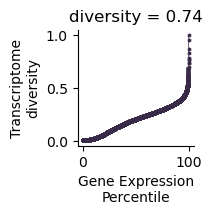

In [66]:
plot_data = scale_with_MinMax(smpl='GTEX-111FC-0126-SM-5N9DL', isoforms_df=np.log2(input_for_transcriptome_div + 1))

fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
sns.lineplot(data=plot_data, x='percentiles', y='minmax', color='#392A48', marker='h', markersize=3, linewidth = 0.5, alpha = 1, markeredgewidth=0,
            ax =ax)
# ax.set_yscale('log')
ax.set(ylabel='Transcriptome\ndiversity', xlabel='Gene Expression\nPercentile', title = 'diversity = {:.2f}'.format(T_DIV['GTEX-111FC-0126-SM-5N9DL']))
sns.despine()

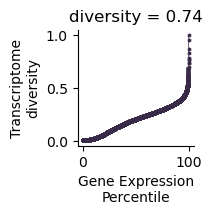

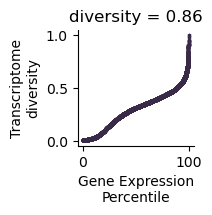

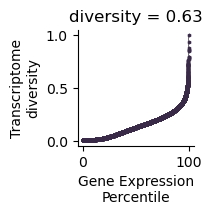

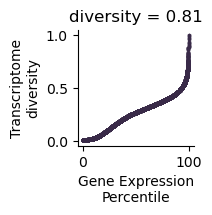

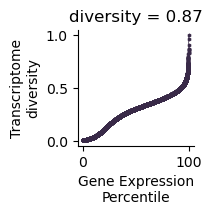

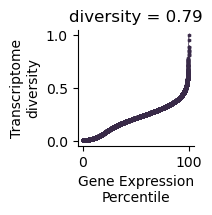

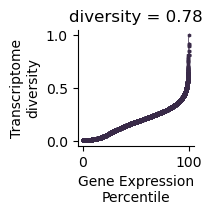

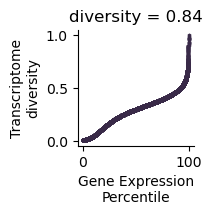

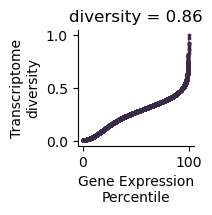

In [67]:
for s in T_DIV.index:
    plot_data = scale_with_MinMax(smpl=s, isoforms_df=np.log2(input_for_transcriptome_div + 1))

    fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
    sns.lineplot(data=plot_data, x='percentiles', y='minmax', color='#392A48', marker='h', markersize=3, linewidth = 0.5, alpha = 1, markeredgewidth=0,
                ax =ax)
    # ax.set_yscale('log')
    ax.set(ylabel='Transcriptome\ndiversity', xlabel='Gene Expression\nPercentile', title = 'diversity = {:.2f}'.format(T_DIV[s]))
    sns.despine()